# Finding a hidden shopping group with tensor PCA
## A complete synthetic sales walkthrough

Can we recover a group of products whose **joint purchasing pattern** is hidden from ordinary covariance PCA? Here, 12 products contain a planted six-product group. Its signal is in **fourth-order correlations**. We compare it with an independent-product control that has no spike.

**The algorithm:** estimate a distinct-index fourth cumulant tensor; lift it to a symmetric Kikuchi matrix on subsets of products; extract large-magnitude eigenpairs; decode them back to product directions. Candidate directions are chosen using **training data only**, then evaluated on separate validation baskets.

We run the whole pipeline on the saved first replicate, at lift levels $\ell=2$ and $\ell=4$. NumPy shows the full spectra, while a small Node.js adapter calls the repository's actual shared solver. The notebook checks the two calculations against each other. At the end, we also inspect the **previously saved** 24-replicate benchmark.

This is a classical algorithm and a controlled recovery example. The synthetic dependencies are parity-like; recovering this group does not yet establish better retail recommendations.

### Before running
Open this file in VS Code with its Jupyter extension, or in Jupyter, using a Python 3 kernel. From the repository root, install the notebook dependencies:

~~~bash
python -m pip install -r applications/sales/requirements-notebook.txt
~~~

Node.js 20 or newer must also be on PATH. Choose **Restart Kernel and Run All**. No data generation or internet access is needed during execution, and the notebook does not overwrite the saved data or results.

## 1. Set up the walkthrough
We locate the repository, load the saved protocol, and define a small JSON interface to the existing JavaScript numerical code. Python handles tables, explicit formulas, full dense eigendecompositions, and plots. All random seeds come from the original protocol.

In [1]:
from pathlib import Path
from itertools import combinations
from math import comb
import json
import shutil
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)

candidates = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
              for candidate in (parent, parent / "tensorpca-repo")]
ROOT = next((p for p in candidates if (p / "src/kikuchi.cjs").is_file()
             and (p / "applications/sales/protocol.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the TensorPCA repository.")
APP = ROOT / "applications/sales"
NODE = shutil.which("node")
if NODE is None:
    raise RuntimeError("Install Node.js 20+ and restart the notebook environment.")
protocol = json.loads((APP / "protocol.json").read_text(encoding="utf-8"))
d, levels = protocol["n_items"], protocol["levels"]
conditions = ("planted", "null")
seeds = {"planted": protocol["seed"], "null": protocol["seed"] + 100000}
colors = {"planted": "#0072B2", "null": "#D55E00"}

def shared(operation, **payload):
    completed = subprocess.run(
        [NODE, str(APP / "notebook_bridge.cjs")],
        input=json.dumps({"operation": operation, "dimension": d, **payload}),
        text=True, capture_output=True, check=True, cwd=ROOT,
    )
    return json.loads(completed.stdout)

print("Repository:", ROOT.name)
print("Python:", sys.version.split()[0], "| Node:", subprocess.check_output(
    [NODE, "--version"], text=True).strip())
print("Products:", d, "| Lift levels:", levels)

No event loop hook running.
Repository: tensorpca-repo
Python: 3.12.4 | Node: v24.22.1
Products: 12 | Lift levels: [2, 4]


## 2. How the datasets were generated — and loading them

Each basket is a binary vector $b\in\{0,1\}^{12}$; $y=2b-1$ gives signed presence/absence. For the planted group $G=\{0,2,4,7,9,11\}$, the generator sampled

$$
P(y)=2^{-12}\left[1+\theta
\sum_{\substack{S\subseteq G\\|S|=4}}\prod_{i\in S}y_i\right],
\qquad \theta=0.12.
$$

The control uses $\theta=0$, so all products are independent Bernoulli$(1/2)$. Both populations have identical distinct moments through order three and covariance $I/4$ in binary coordinates. Only the planted data have nonzero distinct fourth cumulants: $\theta$ on the 15 quartets inside $G$.

The probability bracket ranges from 0.4 to 2.8, so the distribution is valid. The signal sector equals the distinct-index part of $4.32\,v^{\otimes4}$, where $v_i=1/\sqrt6$ on $G$. Repeated-index cumulants are excluded; this is not a full rank-one cumulant tensor.

We **import** four saved CSVs: training and independent validation splits for both conditions, each containing 8,192 baskets. Rows are synthetic baskets, not customer histories. Group labels are retained separately for evaluation only.

In [2]:
item_info = pd.read_csv(APP / "data/items.csv")
items = item_info["item"].tolist()
truth = item_info["planted_weight"].to_numpy(float)
group = np.flatnonzero(item_info["in_planted_group"].to_numpy())
assert items == protocol["items"]
assert group.tolist() == protocol["group"]

data = {}
data_rows = []
for condition in conditions:
    for split in ("train", "validation"):
        frame = pd.read_csv(APP / f"data/{condition}_{split}.csv")
        assert frame.columns.tolist() == items
        assert not frame.isna().any().any()
        assert np.isin(frame.to_numpy(), [0, 1]).all()
        data[condition, split] = frame.to_numpy(dtype=np.int8)
        basket_size = frame.sum(axis=1)
        data_rows.append({
            "condition": condition, "split": split,
            "baskets": len(frame), "products": frame.shape[1],
            "mean basket size": basket_size.mean(),
            "smallest / largest": f"{basket_size.min()} / {basket_size.max()}",
        })

display(pd.DataFrame(data_rows).round(4))
display(pd.DataFrame({
    "product": items,
    "planted train purchase rate": data["planted", "train"].mean(axis=0),
    "control train purchase rate": data["null", "train"].mean(axis=0),
    "planted group (evaluation only)": np.isin(np.arange(d), group),
}).round(4))
print("First five planted training baskets:")
display(pd.DataFrame(data["planted", "train"][:5], columns=items))

,condition,split,baskets,products,mean basket size,smallest / largest
0,planted,train,8192,12,5.9799,0 / 12
1,planted,validation,8192,12,5.9774,0 / 12
2,null,train,8192,12,5.9907,0 / 12
3,null,validation,8192,12,5.9923,0 / 12


,product,planted train purchase rate,control train purchase rate,planted group (evaluation only)
0,Charcoal,0.4993,0.4908,True
1,Oats,0.4896,0.5072,False
2,Meat,0.4955,0.4963,True
3,Milk,0.5037,0.4929,False
4,Marinade,0.4963,0.5020,True
5,Flour,0.4937,0.5049,False
6,Pasta,0.5060,0.4998,False
7,Paper plates,0.4967,0.5026,True
8,Apples,0.5049,0.4934,False
9,Firelighters,0.5005,0.5010,True


First five planted training baskets:


,Charcoal,Oats,Meat,Milk,Marinade,Flour,Pasta,Paper plates,Apples,Firelighters,Coffee,Braai tongs
0,0,0,1,1,1,0,0,0,1,0,0,1
1,0,0,0,1,0,1,0,1,1,1,0,0
2,1,0,1,0,1,0,0,1,1,1,0,1
3,0,0,1,1,1,1,0,1,0,0,1,0
4,0,0,1,1,0,1,1,0,0,1,1,0


## 3. Preprocess: signed coordinates and training centering
The data are complete, binary, and already aligned by product. We map $0/1$ to $-1/+1$, then center each training split by its own empirical means. No whitening or variance scaling is applied: every product has the same population variance, and we want to preserve the product coordinates.

Finite samples still have small nonzero means and correlations. The next step explicitly subtracts these lower-order contributions. Validation baskets only receive the fixed signed transform; they are never used to fit or select a direction.

,condition,max absolute signed mean,max absolute centered mean,largest off-diagonal covariance,mean signed variance
0,planted,0.020752,0.0,0.029363,0.999890
1,null,0.018311,0.0,0.025384,0.999907


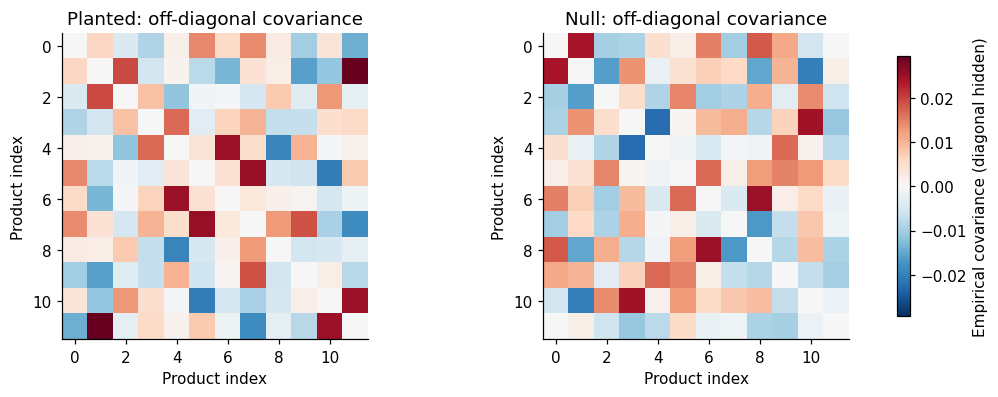

In [3]:
signed = {key: 2 * values.astype(float) - 1 for key, values in data.items()}
centered, covariance = {}, {}
preprocessing_rows = []
for condition in conditions:
    y = signed[condition, "train"]
    centered[condition] = y - y.mean(axis=0)
    covariance[condition] = centered[condition].T @ centered[condition] / len(y)
    offdiag = covariance[condition] - np.diag(np.diag(covariance[condition]))
    preprocessing_rows.append({
        "condition": condition,
        "max absolute signed mean": np.abs(y.mean(axis=0)).max(),
        "max absolute centered mean": np.abs(centered[condition].mean(axis=0)).max(),
        "largest off-diagonal covariance": np.abs(offdiag).max(),
        "mean signed variance": np.trace(covariance[condition]) / d,
    })
display(pd.DataFrame(preprocessing_rows).round(6))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
limit = max(np.abs(covariance[c] - np.diag(np.diag(covariance[c]))).max()
            for c in conditions)
for ax, condition in zip(axes, conditions):
    matrix = covariance[condition].copy()
    np.fill_diagonal(matrix, 0)
    image = ax.imshow(matrix, vmin=-limit, vmax=limit, cmap="RdBu_r")
    ax.set(title=f"{condition.capitalize()}: off-diagonal covariance",
           xlabel="Product index", ylabel="Product index")
fig.colorbar(image, ax=axes, label="Empirical covariance (diagonal hidden)", shrink=0.85)
plt.show()

## 4. Turn baskets into a fourth-order tensor
For four **distinct** products, let $x=y-\bar y$ and
$\widehat\Sigma_{ij}=n^{-1}\sum_t x_{ti}x_{tj}$. We estimate

$$
\widehat C_{ijkl}
=\frac1n\sum_t x_{ti}x_{tj}x_{tk}x_{tl}
-\widehat\Sigma_{ij}\widehat\Sigma_{kl}
-\widehat\Sigma_{ik}\widehat\Sigma_{jl}
-\widehat\Sigma_{il}\widehat\Sigma_{jk}.
$$

This is a plug-in cumulant estimator, not an unbiased finite-sample estimator. We store only the $\binom{12}{4}=495$ unique entries with $i<j<k<l$, in lexicographic order. They specify the retained symmetric sector; repeated-index entries are not estimated.

The explicit Python formula below is checked against the application's histogram/Walsh-transform implementation. Tensor fitting sees no group labels.

In [4]:
quartets = np.array(list(combinations(range(d), 4)), dtype=int)
quartet_masks = (1 << quartets).sum(axis=1)
tensor, tensor_rows = {}, []
for condition in conditions:
    x, cov = centered[condition], covariance[condition]
    fourth = np.array([np.prod(x[:, q], axis=1).mean() for q in quartets])
    i, j, k, l = quartets.T
    tensor[condition] = (fourth - cov[i, j] * cov[k, l]
                       - cov[i, k] * cov[j, l] - cov[i, l] * cov[j, k])
    codes = (data[condition, "train"].astype(np.int64) * (1 << np.arange(d))).sum(axis=1)
    reference = shared("tensor", codes=codes.tolist())["coefficients"]
    error = np.max(np.abs(tensor[condition] - reference))
    assert error < 1e-12
    tensor_rows.append({
        "condition": condition, "order": 4, "modes": d,
        "unique coefficients": len(quartets),
        "minimum": tensor[condition].min(), "maximum": tensor[condition].max(),
        "coefficient L2 norm": np.linalg.norm(tensor[condition]),
        "Python / shared-core max error": error,
    })
display(pd.DataFrame(tensor_rows).round(8))

# These labels are used only to interpret the already fitted tensor.
inside_group = np.isin(quartets, group).all(axis=1)
display(pd.DataFrame([
    {"condition": condition,
     "mean of 15 group quartets": tensor[condition][inside_group].mean(),
     "mean of remaining 480": tensor[condition][~inside_group].mean(),
     "population group coefficient": protocol["theta"] if condition == "planted" else 0}
    for condition in conditions
]).round(5))
for condition in conditions:
    strongest = np.argsort(-np.abs(tensor[condition]))[:8]
    print(f"\n{condition.capitalize()}: eight largest coefficients by absolute value")
    display(pd.DataFrame({
        "products": [" + ".join(items[i] for i in quartets[q]) for q in strongest],
        "cumulant": tensor[condition][strongest],
        "inside reference group": inside_group[strongest],
    }).round(5))

,condition,order,modes,unique coefficients,minimum,maximum,coefficient L2 norm,Python / shared-core max error
0,planted,4,12,495,-0.034574,0.124380,0.497252,0.0
1,null,4,12,495,-0.028945,0.029811,0.243601,0.0


,condition,mean of 15 group quartets,mean of remaining 480,population group coefficient
0,planted,0.11332,0.00049,0.12
1,null,-0.00123,-0.00018,0.00



Planted: eight largest coefficients by absolute value


,products,cumulant,inside reference group
0,Charcoal + Meat + Marinade + Paper plates,0.12438,True
1,Meat + Marinade + Paper plates + Firelighters,0.12360,True
2,Charcoal + Meat + Marinade + Braai tongs,0.12067,True
3,Charcoal + Paper plates + Firelighters + Braai...,0.11743,True
4,Charcoal + Meat + Marinade + Firelighters,0.11741,True
5,Charcoal + Marinade + Firelighters + Braai tongs,0.11669,True
6,Meat + Paper plates + Firelighters + Braai tongs,0.11487,True
7,Charcoal + Marinade + Paper plates + Firelighters,0.10990,True



Null: eight largest coefficients by absolute value


,products,cumulant,inside reference group
0,Charcoal + Firelighters + Coffee + Braai tongs,0.02981,False
1,Charcoal + Marinade + Flour + Pasta,-0.02894,False
2,Oats + Meat + Milk + Pasta,-0.02859,False
3,Charcoal + Milk + Coffee + Braai tongs,0.02654,False
4,Meat + Marinade + Pasta + Braai tongs,-0.02645,False
5,Meat + Pasta + Apples + Firelighters,-0.02621,False
6,Oats + Milk + Pasta + Braai tongs,0.02529,False
7,Oats + Pasta + Paper plates + Braai tongs,0.02499,False


### Inspect the tensor coefficients
The shaded subsets below use the known group **only for interpretation**. The planted tensor should separate its 15 signal quartets from the other 480 entries; the control has no population signal, although finite-sample coefficients are nonzero.

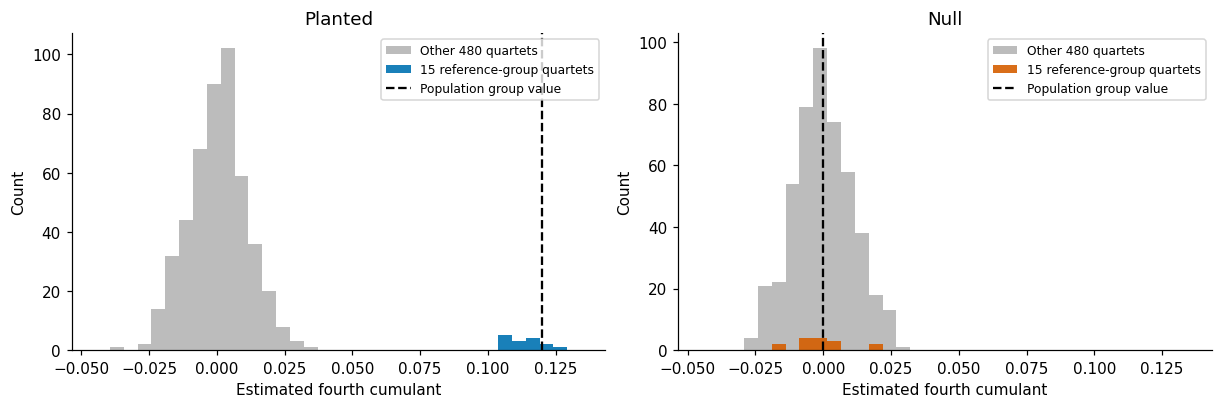

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
bins = np.linspace(min(t.min() for t in tensor.values()) - 0.01,
                   max(t.max() for t in tensor.values()) + 0.01, 36)
for ax, condition in zip(axes, conditions):
    ax.hist(tensor[condition][~inside_group], bins=bins, color="#999999",
            alpha=0.65, label="Other 480 quartets")
    ax.hist(tensor[condition][inside_group], bins=bins, color=colors[condition],
            alpha=0.9, label="15 reference-group quartets")
    ax.axvline(protocol["theta"] if condition == "planted" else 0,
               color="black", linestyle="--", label="Population group value")
    ax.set(title=condition.capitalize(), xlabel="Estimated fourth cumulant", ylabel="Count")
    ax.legend(fontsize=8)
plt.show()

## 5. Construct the Kikuchi lifts
A level-$\ell$ basis state is an $\ell$-element subset of products. The symmetric matrix is

$$
K^{(\ell)}_{U,V}=
\begin{cases}
\widehat C_{U\triangle V}, & |U\triangle V|=4,\\
0, & \text{otherwise}.
\end{cases}
$$

Thus level 2 has dimension 66 and level 4 has dimension 495. Every row has
$\binom{\ell}{2}\binom{12-\ell}{2}$ allowed neighbors. We use the same unnormalized convention as the shared solver.

For this small demonstration we build the full matrices explicitly. The production prototype uses a sparse matrix-vector operation; dense matrices and full spectra become expensive as dimension or lift level grows. Trace zero does **not** mean no signal, since positive and negative eigenvalues cancel.

In [6]:
bases, lifts = {}, {}
coefficient_index = np.full(1 << d, -1, dtype=int)
coefficient_index[quartet_masks] = np.arange(len(quartets))
lift_rows = []

for level in levels:
    bases[level] = list(combinations(range(d), level))
    masks = np.array([sum(1 << i for i in subset) for subset in bases[level]])
    entry_index = coefficient_index[masks[:, None] ^ masks[None, :]]
    allowed = entry_index >= 0
    for condition in conditions:
        K = np.zeros(entry_index.shape)
        K[allowed] = tensor[condition][entry_index[allowed]]
        lifts[condition, level] = K
        degree = comb(level, 2) * comb(d - level, 2)
        expected_norm2 = 6 * comb(d - 4, level - 2) * np.sum(tensor[condition] ** 2)
        assert np.array_equal(K, K.T)
        assert np.trace(K) == 0
        assert np.all(allowed.sum(axis=1) == degree)
        assert np.isclose(np.sum(K ** 2), expected_norm2, rtol=1e-12)
        lift_rows.append({
            "condition": condition, "level": level, "shape": str(K.shape),
            "allowed entries per row": degree, "nonzero entries": np.count_nonzero(K),
            "trace": np.trace(K), "Frobenius norm": np.linalg.norm(K),
        })
display(pd.DataFrame(lift_rows).round(5))
print("First eight level-2 basis states:", bases[2][:8])
for condition in conditions:
    print(f"\n{condition.capitalize()} lift: upper-left 8 x 8 block, level 2")
    display(pd.DataFrame(lifts[condition, 2][:8, :8]).round(4))

,condition,level,shape,allowed entries per row,nonzero entries,trace,Frobenius norm
0,planted,2,"(66, 66)",45,2970,0.0,1.21801
1,null,2,"(66, 66)",45,2970,0.0,0.59670
2,planted,4,"(495, 495)",168,83160,0.0,6.44512
3,null,4,"(495, 495)",168,83160,0.0,3.15743


First eight level-2 basis states: [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8)]

Planted lift: upper-left 8 x 8 block, level 2


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Null lift: upper-left 8 x 8 block, level 2


,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Eigendecompose both conditions and print their full spectra
We compute every eigenvalue and eigenvector with NumPy's symmetric eigensolver. The shared solver keeps the **six eigenpairs with largest absolute eigenvalues**, using dense Jacobi at level 2 and Lanczos at level 4. We compare those eigenvalues, the matrix-vector action, and residuals to the explicit matrices.

The full spectra below are printed in decreasing **signed** order. The separate six-entry lists use decreasing **absolute magnitude**, which is the ordering used for recovery. Compare planted and control spectra within the same level; the two levels use different matrix dimensions and scales.

In [7]:
eigenvalues, eigenvectors, selected = {}, {}, {}
eigen_rows = []
for level in levels:
    for condition in conditions:
        key = condition, level
        K = lifts[key]
        values, vectors = np.linalg.eigh(K)
        eigenvalues[key], eigenvectors[key] = values, vectors
        result = shared("spectrum", coefficients=tensor[condition].tolist(),
                        level=level, seed=seeds[condition] + 2)
        selected[key] = result
        order = np.argsort(-np.abs(values))[:6]
        assert np.allclose(np.sort(values[order]), np.sort(result["values"]),
                           rtol=1e-7, atol=1e-9)
        probe = np.sin(np.arange(len(K)) + 1)
        assert np.allclose(K @ probe, result["probe_product"], atol=1e-11)
        Z = np.array(result["vectors"]).T
        residual = np.max(np.linalg.norm(K @ Z - Z * result["values"], axis=0))
        assert residual < 1e-7 * max(np.max(np.abs(values)), 1e-12)
        eigen_rows.append({
            "condition": condition, "level": level, "eigenvalues": len(values),
            "most negative": values[0], "most positive": values[-1],
            "shared-solver max residual": residual, "solver steps": result["steps"],
        })
        with np.printoptions(precision=5, linewidth=110, threshold=10000):
            print(f"\n{condition.upper()}, level {level}: FULL spectrum ({len(values)} values)")
            print(values[::-1])
            print("Six selected eigenvalues (largest absolute magnitude):")
            print(np.array(result["values"]))
display(pd.DataFrame(eigen_rows))


PLANTED, level 2: FULL spectrum (66 values)
[ 6.92513e-01  1.74363e-01  1.59683e-01  1.54463e-01  1.49820e-01  1.45663e-01  1.36957e-01  1.34343e-01
  1.28468e-01  1.22724e-01  1.04228e-01  1.00614e-01  9.36917e-02  9.08690e-02  8.60809e-02  8.21522e-02
  7.26476e-02  6.50281e-02  6.15341e-02  6.03218e-02  5.76788e-02  5.24258e-02  4.83696e-02  4.62637e-02
  3.88601e-02  3.39567e-02  3.15245e-02  2.47054e-02  2.14246e-02  1.74004e-02  1.43666e-02  1.00583e-02
  8.32957e-03  3.00635e-03  5.65538e-04 -4.42531e-03 -7.53643e-03 -1.23797e-02 -1.76180e-02 -1.97146e-02
 -2.46795e-02 -2.73585e-02 -3.20462e-02 -3.43085e-02 -3.69516e-02 -4.52129e-02 -5.00493e-02 -5.32962e-02
 -5.66417e-02 -5.94200e-02 -6.32357e-02 -7.40229e-02 -7.71942e-02 -7.95175e-02 -8.01237e-02 -8.34366e-02
 -9.21047e-02 -9.92857e-02 -1.05388e-01 -1.11014e-01 -1.26100e-01 -3.37108e-01 -3.46818e-01 -3.49639e-01
 -3.55191e-01 -3.63283e-01]
Six selected eigenvalues (largest absolute magnitude):
[ 0.69251 -0.36328 -0.35519 -0.3

,condition,level,eigenvalues,most negative,most positive,shared-solver max residual,solver steps
0,planted,2,66,-0.363283,0.692513,2.059131e-13,66
1,null,2,66,-0.135135,0.143850,2.186205e-13,66
2,planted,4,495,-0.536429,1.175672,1.807081e-13,60
3,null,4,495,-0.331675,0.359718,4.934208e-11,80


### Visualize the spectra
Ranked curves show isolated spectral extremes; histograms show the bulk of each spectrum. The control supplies a reference for finite-sample noise. These are descriptive comparisons, not a calibrated significance test.

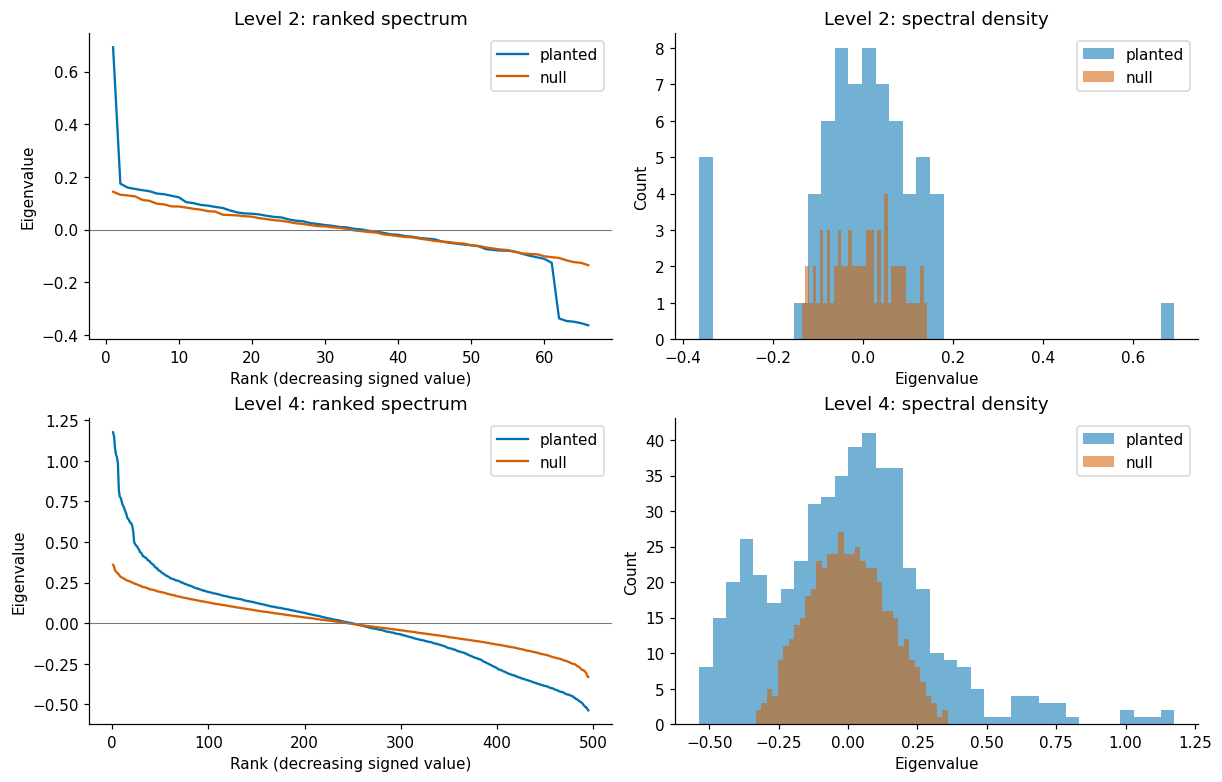

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for row, level in enumerate(levels):
    for condition in conditions:
        values = eigenvalues[condition, level]
        axes[row, 0].plot(np.arange(1, len(values) + 1), values[::-1],
                          color=colors[condition], label=condition)
        axes[row, 1].hist(values, bins=35, alpha=0.55,
                          color=colors[condition], label=condition)
    axes[row, 0].axhline(0, color="#777777", linewidth=0.7)
    axes[row, 0].set(title=f"Level {level}: ranked spectrum",
                     xlabel="Rank (decreasing signed value)", ylabel="Eigenvalue")
    axes[row, 1].set(title=f"Level {level}: spectral density",
                     xlabel="Eigenvalue", ylabel="Count")
    for ax in axes[row]:
        ax.legend()
plt.show()

## 7. Decode lifted eigenvectors into product directions
A lifted eigenvector $z$ lives on subsets, not individual products. For each selected $z$, form
$A_{W,a}=z_{W\cup\{a\}}$ if $a\notin W$, and zero otherwise, where $|W|=\ell-1$.
The one-particle matrix is $\rho=A^\top A/\ell$; it is positive semidefinite and has trace 1.

Each eigenvector $u$ of $\rho$ is a candidate direction. Rank candidates by
$\left|\sum_S\widehat C_S p_S(u)\right|$, where
$p_S(u)=\prod_{i\in S}u_i/\sqrt{\sum_R(\prod_{i\in R}u_i)^2}$.
The winning training contrast determines the answer. No planted labels or validation baskets enter this selection.

The code spells out this decoding, verifies it against the shared recovery API, and adds ordinary covariance PCA as a baseline.

In [9]:
def product_pattern(direction):
    values = np.prod(direction[quartets], axis=1)
    length = np.linalg.norm(values)
    return None if length < 1e-14 else values / length

def decode_candidates(lifted_vectors, level, coefficients):
    lower_basis = list(combinations(range(d), level - 1))
    lower_index = {subset: row for row, subset in enumerate(lower_basis)}
    best = None
    for eigenpair, z in enumerate(lifted_vectors):
        A = np.zeros((len(lower_basis), d))
        for column, subset in enumerate(bases[level]):
            for a in subset:
                W = tuple(i for i in subset if i != a)
                A[lower_index[W], a] = z[column]
        rho = A.T @ A / level
        weights, candidates = np.linalg.eigh(rho)
        assert np.isclose(np.trace(rho), 1, atol=1e-10)
        assert weights.min() > -1e-10
        for candidate in candidates.T:
            pattern = product_pattern(candidate)
            if pattern is None:
                continue
            score = abs(coefficients @ pattern)
            if best is None or score > best["score"]:
                best = {"direction": candidate, "score": score,
                        "density_eigenvalues": weights, "eigenpair": eigenpair}
    return best

directions, decoding_rows = {}, []
for condition in conditions:
    _, vectors = np.linalg.eigh(covariance[condition])
    directions[condition, "PCA"] = vectors[:, -1]
    for level in levels:
        decoded = decode_candidates(selected[condition, level]["vectors"],
                                    level, tensor[condition])
        result = shared("recover", coefficients=tensor[condition].tolist(),
                        level=level, seed=seeds[condition] + 2)
        direction = np.array(result["direction"])
        agreement = float((decoded["direction"] @ direction) ** 2)
        assert np.isclose(agreement, 1, atol=1e-8)
        assert np.isclose(decoded["score"], result["info"]["score"], rtol=1e-8)
        directions[condition, f"TensorPCA l={level}"] = direction
        decoding_rows.append({
            "condition": condition, "level": level,
            "winning eigenpair (1-based)": decoded["eigenpair"] + 1,
            "training contrast": decoded["score"],
            "explicit / shared squared cosine": agreement,
            "largest one-particle eigenvalue": decoded["density_eigenvalues"][-1],
        })
display(pd.DataFrame(decoding_rows).round(7))

,condition,level,winning eigenpair (1-based),training contrast,explicit / shared squared cosine,largest one-particle eigenvalue
0,planted,2,1,0.439055,1.0,0.830385
1,planted,4,6,0.408011,1.0,0.504118
2,null,2,4,0.049062,1.0,0.421005
3,null,4,2,0.043762,1.0,0.364867


## 8. Inspect product weights and recovery
A direction's global sign is unidentifiable for an even-order tensor. We align signs to the known reference **for display only**. Squared cosine is invariant to that sign, and a uniform random direction has expected squared alignment $1/12$.

For the planted data this measures recovery accuracy. The control contains no true direction, so its alignment and top-six overlap refer only to the fixed reference group. The known group size six is used only for scoring and displaying a six-product shortlist.

,condition,method,squared alignment to reference,reference items in top six,validation contrast
0,planted,PCA,0.037917,2,0.004236
1,planted,TensorPCA l=2,0.992394,6,0.455337
2,planted,TensorPCA l=4,0.966378,6,0.412276
3,null,PCA,0.027084,3,-0.006358
4,null,TensorPCA l=2,0.005005,3,-0.028019
5,null,TensorPCA l=4,0.002966,2,-0.000633



Planted: level-4 top-six products
Firelighters, Meat, Paper plates, Braai tongs, Charcoal, Marinade

Null: level-4 top-six products
Coffee, Flour, Marinade, Charcoal, Milk, Apples


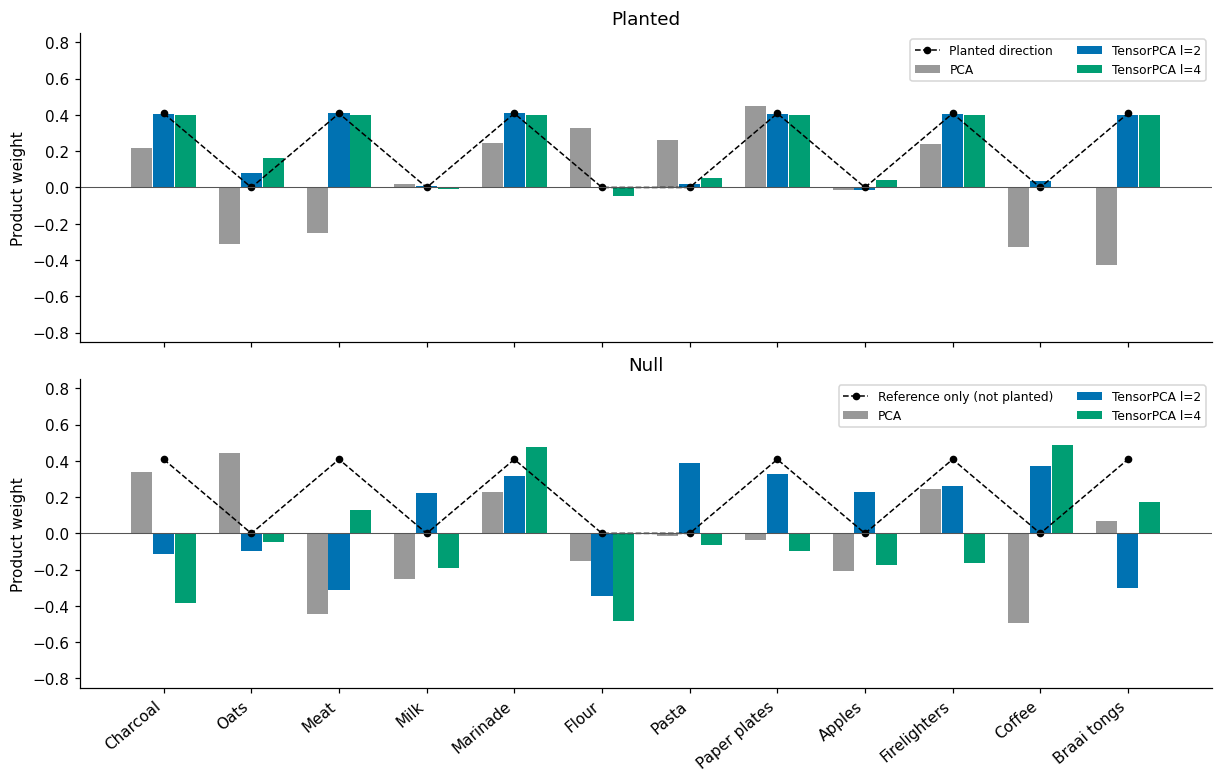

In [10]:
methods = ["PCA", "TensorPCA l=2", "TensorPCA l=4"]
raw_validation_fourth = {
    condition: np.array([np.prod(signed[condition, "validation"][:, q], axis=1).mean()
                         for q in quartets])
    for condition in conditions
}
evaluation_rows = []
for condition in conditions:
    for method in methods:
        direction = directions[condition, method]
        top = np.argsort(-np.abs(direction))[:len(group)]
        pattern = product_pattern(direction)
        evaluation_rows.append({
            "condition": condition, "method": method,
            "squared alignment to reference": (direction @ truth) ** 2,
            "reference items in top six": len(set(top) & set(group)),
            "validation contrast": float(pattern @ raw_validation_fourth[condition]),
        })
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.round(6))

for condition in conditions:
    print(f"\n{condition.capitalize()}: level-4 top-six products")
    top = np.argsort(-np.abs(directions[condition, "TensorPCA l=4"]))[:len(group)]
    print(", ".join(items[i] for i in top))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
x = np.arange(d)
method_colors = ["#999999", "#0072B2", "#009E73"]
for ax, condition in zip(axes, conditions):
    for offset, method, color in zip([-0.25, 0, 0.25], methods, method_colors):
        u = directions[condition, method]
        aligned = u * (1 if u @ truth >= 0 else -1)
        ax.bar(x + offset, aligned, width=0.24, label=method, color=color)
    label = "Planted direction" if condition == "planted" else "Reference only (not planted)"
    ax.plot(x, truth, "k--o", markersize=4, linewidth=1, label=label)
    ax.set(title=condition.capitalize(), ylabel="Product weight", ylim=(-0.85, 0.85))
    ax.axhline(0, color="#555555", linewidth=0.7)
    ax.legend(fontsize=8, ncol=2)
axes[-1].set_xticks(x, items, rotation=40, ha="right")
plt.show()

## 9. Test the recovered direction on held-out baskets
A solver will return a direction even for noise. We therefore evaluate the predetermined **level-4** direction on independent validation baskets. The statistic is the absolute mean normalized fourth-order product pattern along the fixed direction.

We independently permute each validation column 199 times. This preserves each product's frequency while destroying joint dependencies. The direction stays fixed; validation data were not used for fitting. The permutation $p$-value is $(1+\#\{\text{permuted statistic}\geq\text{observed}\})/200$, so its minimum is 0.005.

This tests held-out dependence, not recommendation quality. The statistic is a raw signed fourth moment; its population equals the projected cumulant in this specific model because the lower distinct moments vanish.

,condition,validation baskets,permutations,observed absolute contrast,p-value
0,planted,8192,199,0.412276,0.005
1,null,8192,199,0.000633,0.960


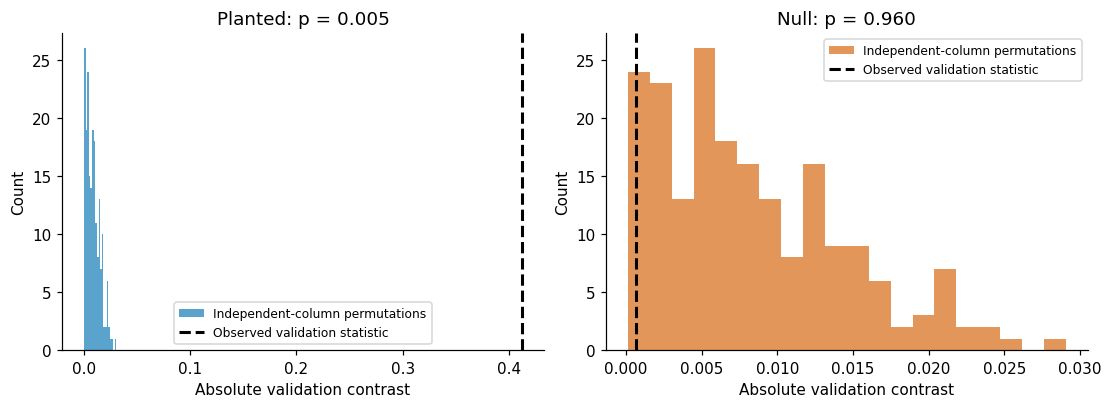

In [11]:
permutations, permutation_rows = {}, []
for condition in conditions:
    codes = (data[condition, "validation"].astype(np.int64)
             * (1 << np.arange(d))).sum(axis=1)
    result = shared("permutation", codes=codes.tolist(),
                    direction=directions[condition, "TensorPCA l=4"].tolist(),
                    count=protocol["permutations"], seed=seeds[condition] + 3)
    permutations[condition] = result
    expected_observed = abs(product_pattern(directions[condition, "TensorPCA l=4"])
                            @ raw_validation_fourth[condition])
    assert np.isclose(result["observed"], expected_observed, atol=1e-12)
    permutation_rows.append({
        "condition": condition, "validation baskets": len(codes),
        "permutations": result["count"], "observed absolute contrast": result["observed"],
        "p-value": result["p_value"],
    })
display(pd.DataFrame(permutation_rows).round(6))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, condition in zip(axes, conditions):
    result = permutations[condition]
    ax.hist(result["null_statistics"], bins=20, color=colors[condition], alpha=0.65,
            label="Independent-column permutations")
    ax.axvline(result["observed"], color="black", linestyle="--", linewidth=2,
               label="Observed validation statistic")
    ax.set(title=f"{condition.capitalize()}: p = {result['p_value']:.3f}",
           xlabel="Absolute validation contrast", ylabel="Count")
    ax.legend(fontsize=8)
plt.show()

## 10. Put this example beside the saved multi-seed benchmark
Everything above was recomputed from the four imported CSVs for the first replicate. This section **loads the existing benchmark**, rather than regenerating data: 24 planted replicates at four nested training sizes, plus 24 independent-product controls at 8,192 training baskets.

Error bars are **one standard deviation across seeds**, not confidence intervals. The within-seed sample sizes are nested. Level 2 is more accurate than level 4 in this particular experiment; a higher lift is not automatically better.

,condition,method,replicates,squared_cosine_mean,squared_cosine_sd,exact_support_mean,validation_contrast_mean
9,planted,PCA,24,0.04107,0.05856,0.0,0.00490
10,planted,TensorPCA l=2,24,0.99691,0.00177,1.0,0.46455
11,planted,TensorPCA l=4,24,0.98263,0.00717,1.0,0.43992
12,null,PCA,24,0.07041,0.07603,0.0,-0.00165
13,null,TensorPCA l=2,24,0.04639,0.05620,0.0,-0.00260
14,null,TensorPCA l=4,24,0.04508,0.09627,0.0,-0.00368


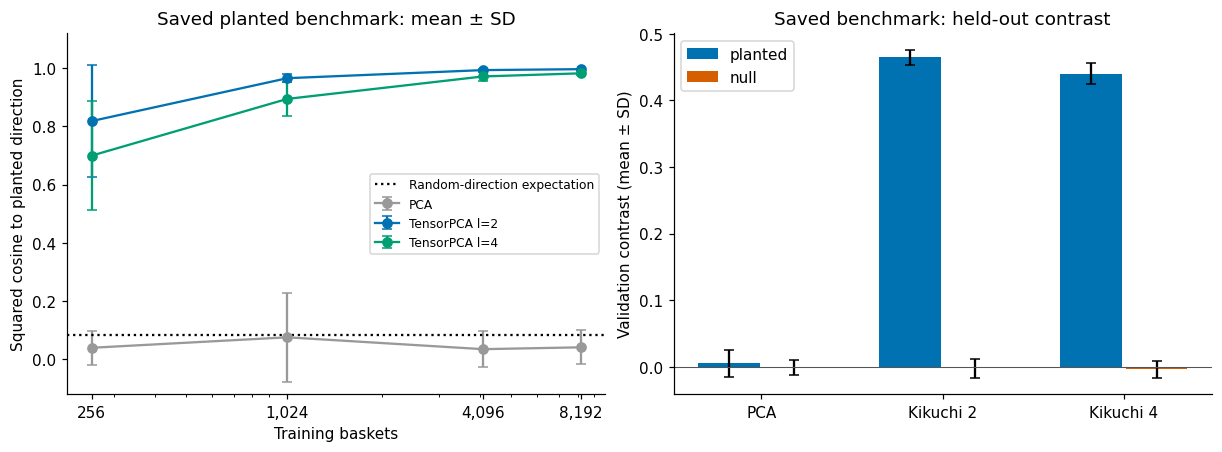

In [12]:
# Preserve the literal condition label 'null' instead of parsing it as missing data.
benchmark = pd.read_csv(APP / "results/summary.csv", keep_default_na=False)
display(benchmark.loc[benchmark["n_train"] == 8192, [
    "condition", "method", "replicates", "squared_cosine_mean",
    "squared_cosine_sd", "exact_support_mean", "validation_contrast_mean",
]].round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for method, color in zip(methods, method_colors):
    rows = benchmark[(benchmark["condition"] == "planted")
                     & (benchmark["method"] == method)].sort_values("n_train")
    axes[0].errorbar(rows["n_train"], rows["squared_cosine_mean"],
                    yerr=rows["squared_cosine_sd"], marker="o", capsize=3,
                    label=method, color=color)
axes[0].axhline(1 / d, color="black", linestyle=":", label="Random-direction expectation")
axes[0].set(xscale="log", xlabel="Training baskets", ylabel="Squared cosine to planted direction",
            title="Saved planted benchmark: mean ± SD", ylim=(-0.12, 1.12))
axes[0].set_xticks(protocol["sample_sizes"], [f"{n:,}" for n in protocol["sample_sizes"]])
axes[0].legend(fontsize=8)
for condition, offset in [("planted", -0.18), ("null", 0.18)]:
    rows = benchmark[(benchmark["condition"] == condition)
                     & (benchmark["n_train"] == 8192)].set_index("method").loc[methods]
    axes[1].bar(np.arange(3) + offset, rows["validation_contrast_mean"], width=0.34,
                yerr=rows["validation_contrast_sd"], capsize=3,
                color=colors[condition], label=condition)
axes[1].set_xticks(np.arange(3), ["PCA", "Kikuchi 2", "Kikuchi 4"])
axes[1].set(title="Saved benchmark: held-out contrast",
            ylabel="Validation contrast (mean ± SD)")
axes[1].axhline(0, color="#555555", linewidth=0.7)
axes[1].legend()
plt.show()

## 11. Check the walkthrough against the saved experiment
We verify that importing the CSVs, estimating tensors, recovering directions, and running validation reproduces the saved first-replicate results. Earlier assertions checked lift identities, dense/shared eigenvalues, eigenvector residuals, and the explicit decoder. These comparisons allow floating-point differences between numerical libraries and ignore global vector sign.

In [13]:
saved = json.loads((APP / "results/results.json").read_text(encoding="utf-8"))
for condition in conditions:
    example = saved["examples"][condition]
    assert np.allclose(tensor[condition], example["coefficients"], atol=1e-12)
    for method in methods:
        saved_direction = np.array(example["directions"][method])
        assert np.isclose((saved_direction @ directions[condition, method]) ** 2,
                          1, atol=1e-7)
        old = next(row for row in saved["rows"] if row["condition"] == condition
                   and row["replicate"] == 0 and row["n_train"] == 8192
                   and row["method"] == method)
        new = next(row for row in evaluation_rows
                   if row["condition"] == condition and row["method"] == method)
        assert np.isclose(old["squared_cosine"], new["squared alignment to reference"], atol=1e-7)
        assert np.isclose(old["validation_contrast"], new["validation contrast"], atol=1e-7)
        assert np.isclose(old["support_recall"], new["reference items in top six"] / len(group))
    assert permutations[condition]["p_value"] == saved["permutations"][condition]["p_value"]

print("PASS: both imported conditions reproduce their saved first-replicate results.")
print("PASS: explicit cumulants, Kikuchi matrices, eigenspectra, and decoding agree with the shared core.")
print("PASS: held-out permutation tests reproduce the saved p-values.")
print("No saved datasets or benchmark results were overwritten.")

PASS: both imported conditions reproduce their saved first-replicate results.
PASS: explicit cumulants, Kikuchi matrices, eigenspectra, and decoding agree with the shared core.
PASS: held-out permutation tests reproduce the saved p-values.
No saved datasets or benchmark results were overwritten.


## What this shows
The fourth-order method can recover this deliberately hidden product group even when population covariance has no preferred direction. The independent-product control can still produce a visually structured fitted direction; held-out validation is what distinguishes reproducible dependence from a noise fit here.

The six products are an illustrative subgroup, not a causal shopping explanation. These dense, balanced baskets do not yet model unequal popularity, sparse purchases, overlapping groups, changing trends, or recommendation lift. Those are follow-up applications, not conclusions of this experiment.

### Files and reproduction
- The shared solver is in **src/kikuchi.cjs**.
- The notebook adapter is **applications/sales/notebook_bridge.cjs**; it only exchanges JSON and does not write files.
- The complete original multi-seed experiment can be regenerated from the repository root with **node applications/sales/run_experiment.cjs**.
- A fresh-kernel notebook check is available as **python scripts/check_notebook.py**.
- See **docs/algorithm.md** for the exact Kikuchi convention and limitations, and **applications/sales/README.md** for dataset provenance.